In [1]:
from gaussian_beam import *
from adjointold import *
from plot import *
import matplotlib.pyplot as plt

In [2]:
path = "base/delta_f_targ_0.05_f_init_0.045_ell_0_wl_1e-06_f_num_25_conic_-1_nr_1000_r_maxf_5_nzf_501_dz_0.02_steps_5000_lr_5e-11_delta_1_tol_0.01_sg_0_order_0.txt"
params = initialize_variables_from_file(path)
dirname = (path.split("/")[-1])[:-4]
path = "runs/" + dirname

In [3]:
f = params["f_targ"]  # focal length of lens
ell = 0  # order of Bessel J function
mir_i = params["f_init"]  # initial mirror focal length
conic = params["conic"]

# Beam Parameters
wl = params["wl"]  # wavelength
k0 = 2 * np.pi / wl  # k=2*pi/wavelength
fn = params["f_num"]  # f#
w0 = f / (2 * fn)  # initial spot size
rmax = params["r_maxf"] * w0  # the max value of r
nr = params["nr"]  # number of points in r
zR = np.pi * w0**2 / wl  # Initial rayleigh length
wR = 2 / np.pi * fn * wl  # Diffraction limited spot size

# Distance parameters
dz = params["dz"]
nzf = params["nzf"]
zF = np.linspace(f - dz, f + dz, nzf)
fl = len(zF) // 2  # focal length index

# Guess parameters
OoM = math.floor(math.log(w0**2, 10))  # order of magnitude of w0^2
w_guess = 10**OoM  # guess for the spot size
steps = params["steps"]  # max number of steps algorithm is allowed
lr = params["lr"]  # learning rate
tol = params["tol"]  # tolerance
delta = params["delta"]  # weighting function in r

In [4]:
# Hankel
[r, k] = DHTarrays(nr, rmax, ell)
[T_R2K, T_K2R] = DHTtransformMatrix(nr, rmax, ell)

In [5]:
phi_I = 1j * np.exp(-((r / w0) ** 2))
zm_t = create_starting_optic(r, 2 * f)  # target mirror
ftf_t = forward_propagation(
    w0, r, k, phi_I, T_R2K, T_K2R, zF, zm_t
)  # Target profile defined using target mirror

zm_r = create_starting_optic(r, 2 * mir_i, k=conic)  # initial mirror
ftf_r = forward_propagation(w0, r, k, phi_I, T_R2K, T_K2R, zF, zm_r)


In [6]:
# Adjoint
psi_hat = adjoint(
    r, 2 * wR, k, k0, zF, f - dz, f + dz, ftf_r, ftf_t, T_R2K, T_K2R, delta
)
psi = T_K2R @ psi_hat
grad = np.real(gradient(k0, phi_I, psi, zm_r))

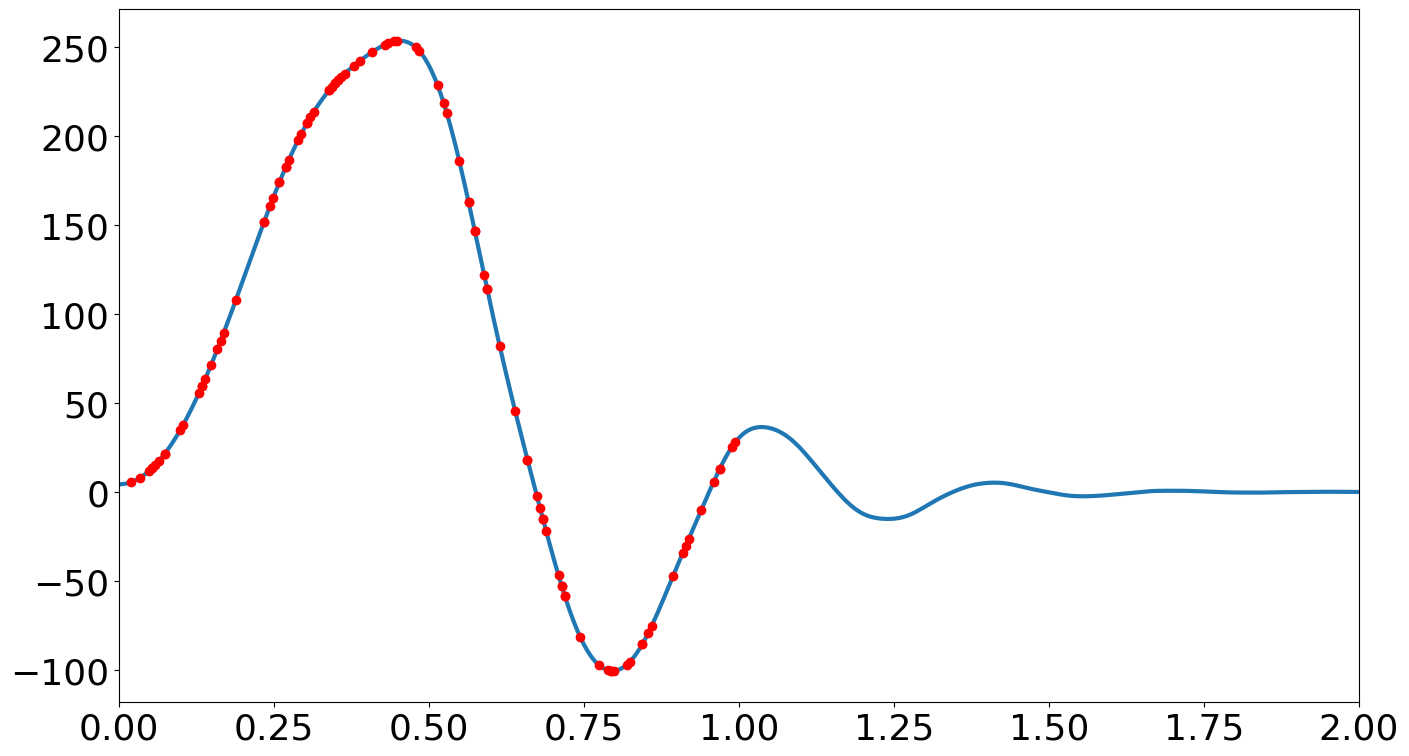

In [7]:
plt.plot(r/w0, grad)
plt.xlim(0,2)

#choose 10 random points on grad on limit and plot them
indices = np.random.choice(len(grad)//5, 100)
for i in indices:
    plt.plot(r[i]/w0, grad[i], 'ro')
plt.savefig('grad.png')

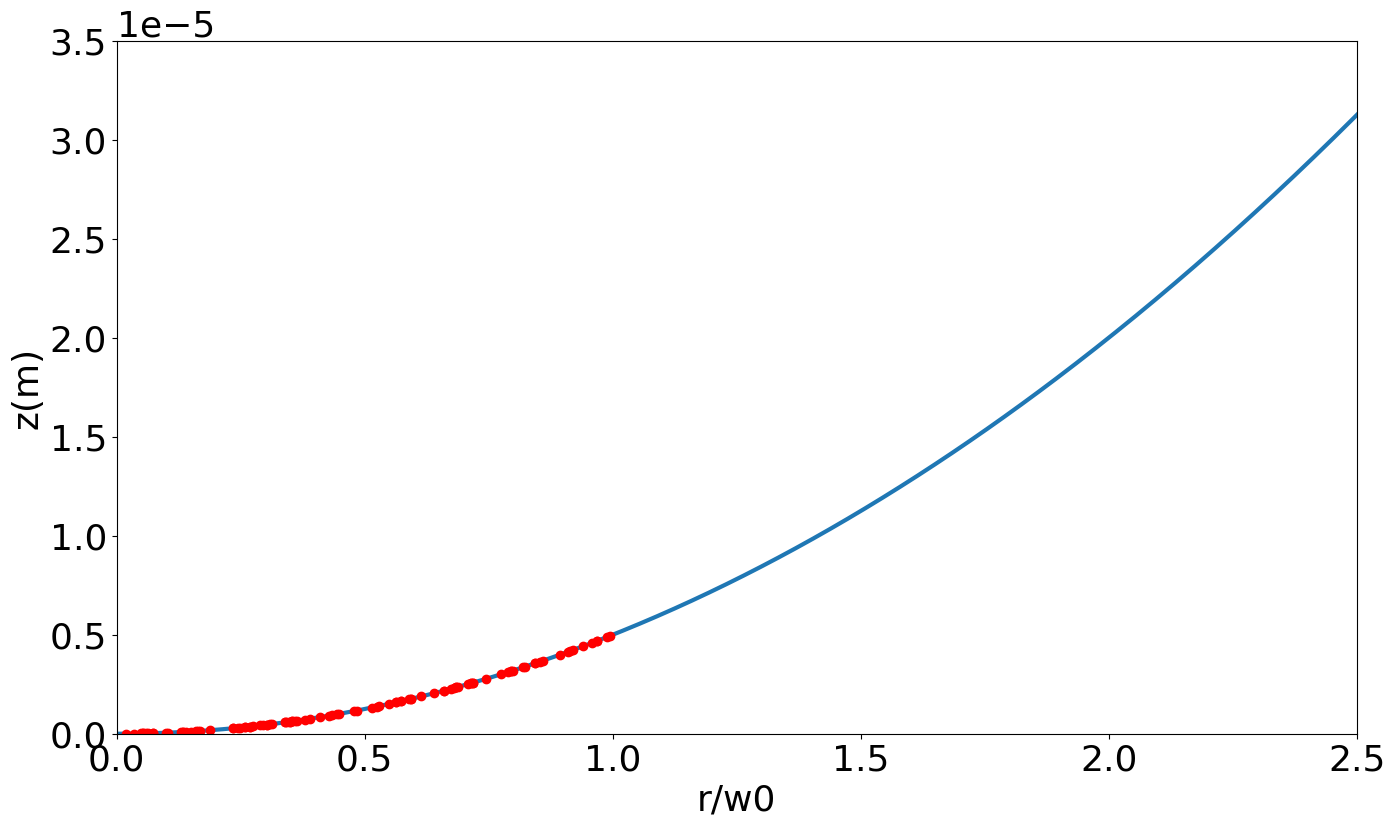

In [8]:
plt.plot(r/w0, zm_t)
for i in indices:
    plt.plot(r[i]/w0, zm_t[i], 'ro')
plt.xlim(0,2.5)
plt.ylim(0,3.5e-5)
plt.xlabel('r/w0')
plt.ylabel('z(m)')
# sci notation y axis
plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

plt.savefig('sample_zm')
plt.show()

In [9]:
def zern_pols(rho):
    pols = [
        np.ones_like(rho),  # 1st polynomial is constant
        np.sqrt(3) * (2 * rho**2 - 1),  # 2nd polynomial
        np.sqrt(5) * (6 * rho**4 - 6 * rho**2 + 1)  # 3rd polynomial
    ]
    return np.column_stack(pols)  

In [10]:
data_r=r[indices]/w0
data_grad=grad[indices]
data_mirror=zm_t[indices]
A=zern_pols(data_r)

In [11]:
np.shape(grad)

(1000,)

In [12]:
np.shape(zern_pols(r/w0))

(1000, 3)

In [13]:
np.dot(grad, zern_pols(r/w0))

array([ 16165.62527403, -22672.22262374,  11326.3680812 ])

In [14]:
print(A)

[[ 1.         -0.93767399 -0.13502215]
 [ 1.         -1.71319772  2.16344769]
 [ 1.          1.52055558  1.4669604 ]
 [ 1.         -0.31798283 -1.00498613]
 [ 1.         -1.41227667  1.11191318]
 [ 1.         -1.63911552  1.88578757]
 [ 1.         -1.47232225  1.30556495]
 [ 1.          0.18512633 -1.079717  ]
 [ 1.         -1.07998981  0.18601625]
 [ 1.         -0.63055776 -0.67350023]
 [ 1.          1.03642186  0.08292489]
 [ 1.         -1.44307927  1.21024695]
 [ 1.         -0.59113389 -0.727349  ]
 [ 1.         -0.53069841 -0.80315   ]
 [ 1.          0.47915904 -0.86134078]
 [ 1.         -1.67004809  2.00023058]
 [ 1.          0.79416005 -0.41290093]
 [ 1.         -1.29833737  0.76661345]
 [ 1.         -0.22804443 -1.05989145]
 [ 1.         -0.68839387 -0.58821321]
 [ 1.         -1.7220356   2.1973914 ]
 [ 1.          1.13012935  0.30991048]
 [ 1.         -1.15298894  0.36826195]
 [ 1.         -0.51020666 -0.82699762]
 [ 1.         -1.31051111  0.8021216 ]
 [ 1.         -1.54267868

In [15]:
print(A.T @ A)
#print the determinant
print(np.linalg.det(A.T @ A))

[[100.         -65.62309242  48.98970757]
 [-65.62309242 143.81772653 -92.94644371]
 [ 48.98970757 -92.94644371 161.7539166 ]]
1018285.9944709941


In [16]:
#calculate (A^T*A)^-1
ATA_inv=np.linalg.inv(A.T @ A)
print(ATA_inv)

[[ 0.01436143  0.00595253 -0.00092916]
 [ 0.00595253  0.01352803  0.00597061]
 [-0.00092916  0.00597061  0.00989445]]


In [17]:
x=ATA_inv @ A.T @ data_grad
print(x)

[ 39.70269096 -75.13149077  -9.58468145]


In [18]:
w=ATA_inv @ A.T @ data_mirror
print(w)

[ 2.50000000e-06  1.44337567e-06 -2.11758237e-22]


In [24]:
zp=ATA_inv @ A.T
print(np.shape(zp))
print(zp @ A)

(3, 100)
[[ 1.00000000e+00  3.86450211e-16 -3.45709573e-16]
 [ 1.07552856e-16  1.00000000e+00 -8.43733553e-17]
 [-9.54097912e-17  9.34363796e-17  1.00000000e+00]]


In [19]:
print(1/2/np.sqrt(3))

0.2886751345948129


In [20]:
def zernike_fit(rho, x):
    pols = zern_pols(rho)
    return np.dot(pols, x)

In [59]:
np.shape(A)
print(data_grad@A)

[  8431.07911701 -12519.79149615   7377.86833286]


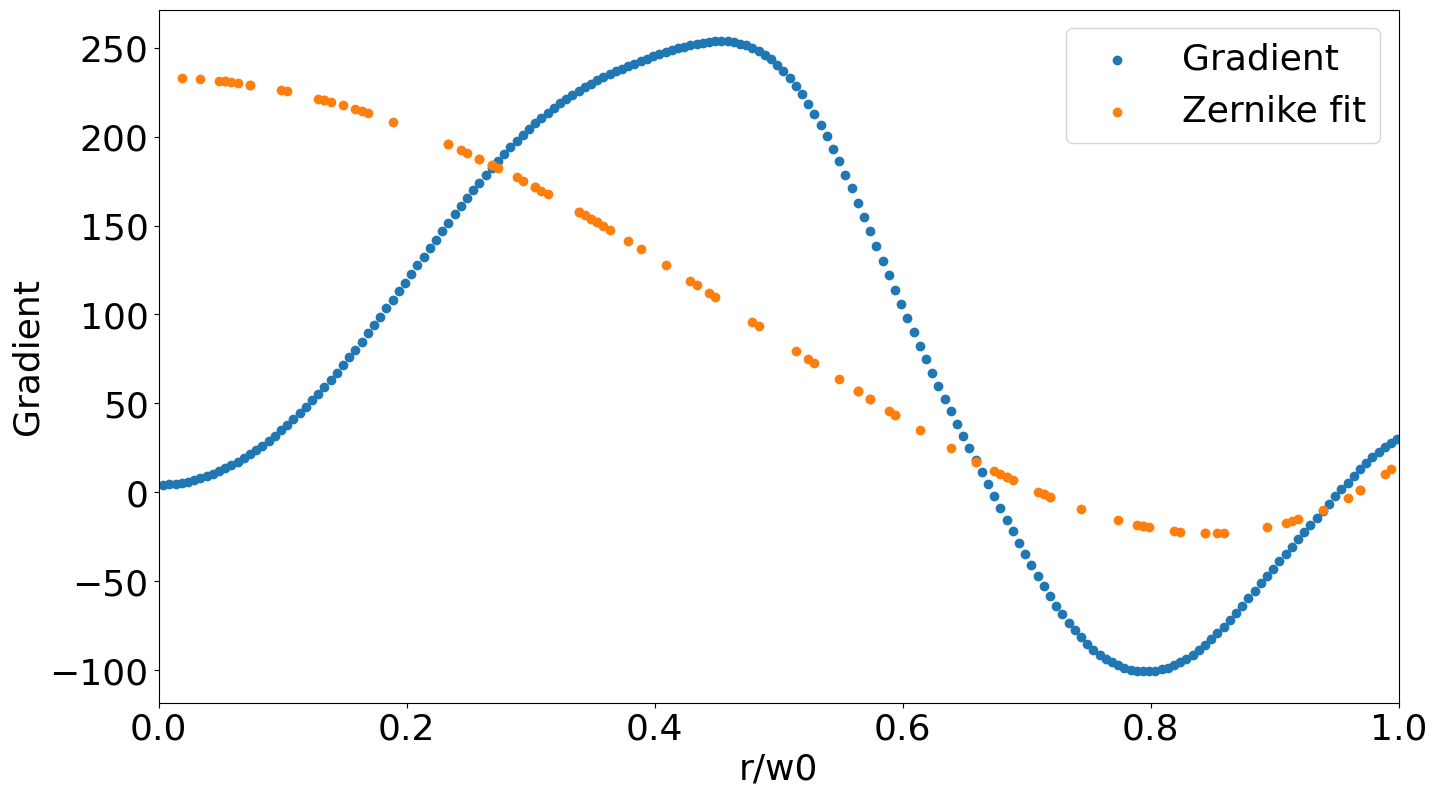

In [56]:
#plot the gradient vs the zernike polynomials
plt.scatter(r/w0, grad , label='Gradient')
# plt.plot(r/w0, zernike_fit(r/w0, x), label='Zernike fit')
plt.xlim(0,1)
# plt.ylim(-150,350)
# use polyfit to fit grad to 0th, 2nd, 4th order polynomials

plt.scatter(data_r, A@(data_grad@A)*5e-3, label='Zernike fit')
plt.xlabel('r/w0')
plt.ylabel('Gradient')
plt.legend()

plt.savefig('zernike_fit_grad.png')
plt.show()

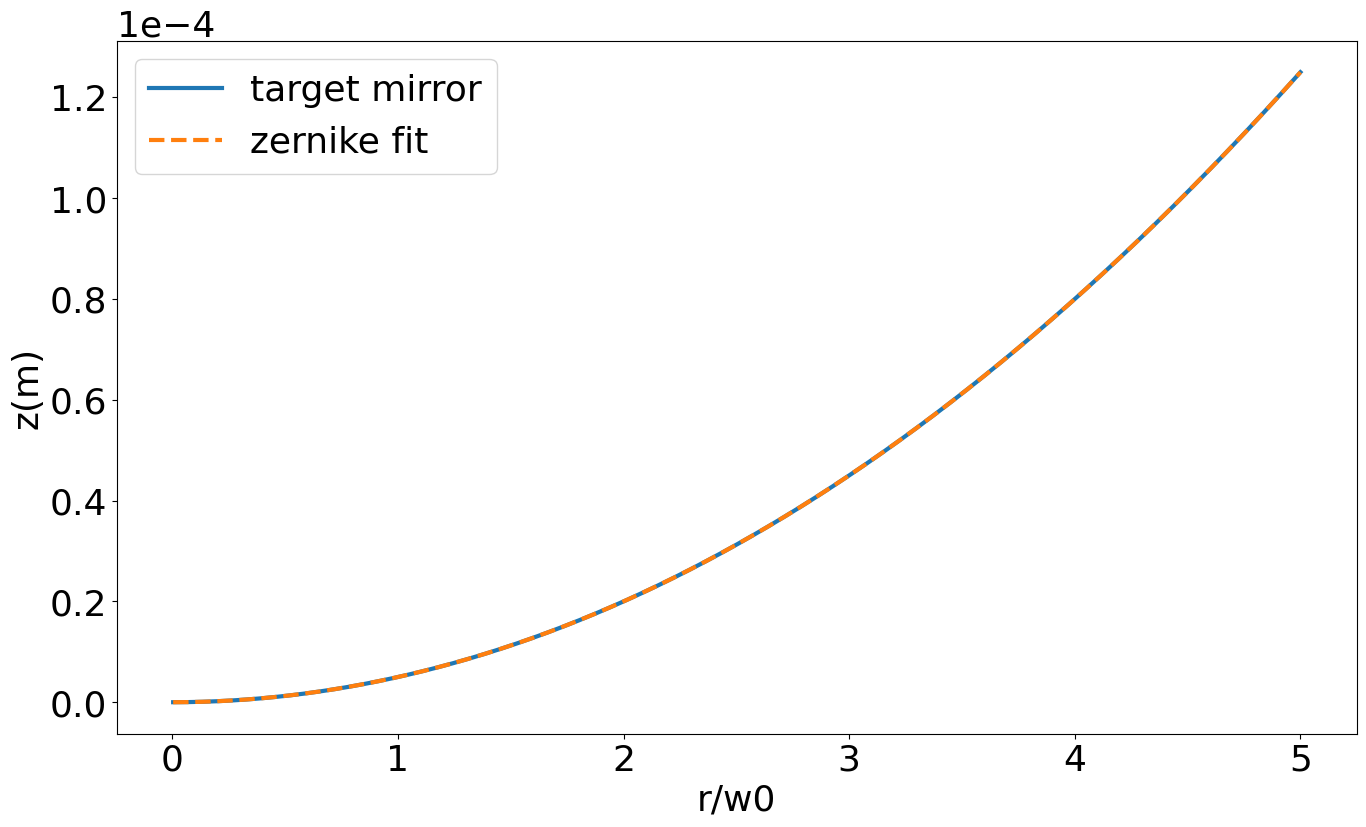

In [22]:
plt.plot(r/w0, zm_t, label='target mirror')
plt.plot(r/w0, zernike_fit(r/w0, w),linestyle='dashed',label='zernike fit')
# plt.xlim(0,0.002)
# plt.ylim(-150,350)
plt.legend()
plt.xlabel('r/w0')
plt.ylabel('z(m)')
# sci notation y axis
plt.ticklabel_format(style='sci', axis='y', scilimits=(0,0))

plt.savefig('zernike_fit_mirror.png')